In [3]:
import requests
import pandas as pd
import time
from datetime import datetime

In [2]:
url = "https://opensky-network.org/api/states/all"

response = requests.get(url, timeout=30)

print("HTTP状态码：", response.status_code)

data = response.json()

print("采集时间：", data["time"])
print("飞机数量：", len(data["states"]))

HTTP状态码： 200
采集时间： 1794972609
飞机数量： 6634


In [3]:
#连续请求 OpenSky，采集一段时间内飞机的各种数据
all_data = []

for i in range(10):
    try:
        response = requests.get(url, timeout=30)
        data = response.json()

        timestamp = data["time"]

        for state in data["states"]:
            state.append(timestamp)
            all_data.append(state)

        print(
            f"第 {i+1}/10 次采集完成，"
            f"飞机数：{len(data['states'])}"
        )

    except Exception as e:
        print("采集失败：", e)

    if i < 9:
        time.sleep(30)

第 1/10 次采集完成，飞机数：6624
第 2/10 次采集完成，飞机数：6624
第 3/10 次采集完成，飞机数：6629
第 4/10 次采集完成，飞机数：6648
第 5/10 次采集完成，飞机数：6612
第 6/10 次采集完成，飞机数：6588
第 7/10 次采集完成，飞机数：6571
第 8/10 次采集完成，飞机数：6556
第 9/10 次采集完成，飞机数：6552
第 10/10 次采集完成，飞机数：6527


In [4]:
columns = [
    "icao24",
    "callsign",
    "origin_country",
    "time_position",
    "last_contact",
    "longitude",
    "latitude",
    "baro_altitude",
    "on_ground",
    "velocity",
    "true_track",
    "vertical_rate",
    "sensors",
    "geo_altitude",
    "squawk",
    "spi",
    "position_source",
    "snapshot_time"
]

df_track = pd.DataFrame(all_data, columns=columns)

print("连续 ADS-B 数据规模：", df_track.shape)

display(df_track.head())

连续 ADS-B 数据规模： (65931, 18)


,icao24,callsign,origin_country,time_position,last_contact,longitude,latitude,baro_altitude,on_ground,velocity,true_track,vertical_rate,sensors,geo_altitude,squawk,spi,position_source,snapshot_time
0,ac96b8,AAL1466,United States,1.794972e+09,1794972450,-87.8950,41.9840,NaN,True,7.46,180.00,NaN,None,NaN,5527,False,0,1794972621
1,408120,VIR12E,United Kingdom,1.794973e+09,1794972618,-71.0126,42.3688,NaN,True,5.92,135.00,NaN,None,NaN,NaN,False,0,1794972621
2,a2e5ec,SKW3800,United States,1.794973e+09,1794972606,-111.9942,40.7911,NaN,True,6.43,174.38,NaN,None,NaN,4310,False,0,1794972621
3,88044a,AIQ3035,Thailand,1.794973e+09,1794972619,99.7416,10.3990,11292.84,False,227.31,17.25,0.00,None,NaN,4557,False,0,1794972621
4,7c6b2f,JST236,Australia,1.794973e+09,1794972620,173.3972,-41.7773,10439.40,False,212.94,22.29,1.95,None,10439.4,5047,False,0,1794972621


In [5]:
df_track = df_track.drop(columns=["sensors"])

print("最终数据规模：", df_track.shape)

最终数据规模： (65931, 17)


In [6]:
track_path = "D:/adsb-flight-analysis/data/raw/opensky_trajectory_raw.csv"

df_track.to_csv(
    track_path,
    index=False,
    encoding="utf-8-sig"
)

print("连续 ADS-B 数据保存成功！")

连续 ADS-B 数据保存成功！


In [7]:
print("数据规模：", df_track.shape)

print("采样时间点数量：", df_track["snapshot_time"].nunique())

print("飞机数量：", df_track["icao24"].nunique())

print(
    "时间范围：",
    df_track["snapshot_time"].min(),
    "→",
    df_track["snapshot_time"].max()
)

数据规模： (65931, 17)
采样时间点数量： 10
飞机数量： 7194
时间范围： 1794972621 → 1794972924


In [8]:
print("每个时间点的飞机数量：")

display(
    df_track.groupby("snapshot_time")["icao24"]
    .nunique()
)

每个时间点的飞机数量：


snapshot_time
1794972621    6624
1794972653    6624
1794972689    6629
1794972723    6648
1794972754    6612
1794972791    6588
1794972816    6571
1794972850    6556
1794972875    6552
1794972924    6527
Name: icao24, dtype: int64

In [9]:
df_track = df_track.sort_values(
    ["icao24", "snapshot_time"]
).copy()

print("排序完成")
display(df_track.head())

排序完成


,icao24,callsign,origin_country,time_position,last_contact,longitude,latitude,baro_altitude,on_ground,velocity,true_track,vertical_rate,geo_altitude,squawk,spi,position_source,snapshot_time
290,00b1f4,SAA280,South Africa,1.794973e+09,1794972620,114.7344,-31.6585,5166.36,False,158.30,107.79,-4.88,5273.04,5610,False,0,1794972621
6914,00b1f4,SAA280,South Africa,1.794973e+09,1794972653,114.7882,-31.6661,4960.62,False,155.43,88.29,-5.85,5067.30,5610,False,0,1794972653
13540,00b1f4,SAA280,South Africa,1.794973e+09,1794972689,114.8464,-31.6638,4701.54,False,155.04,87.15,-6.50,4792.98,5610,False,0,1794972689
20168,00b1f4,SAA280,South Africa,1.794973e+09,1794972723,114.9023,-31.6611,4480.56,False,152.56,86.52,-6.18,4564.38,5610,False,0,1794972723
26816,00b1f4,SAA280,South Africa,1.794973e+09,1794972753,114.9498,-31.6585,4312.92,False,149.03,86.04,-5.85,4389.12,5610,False,0,1794972754


In [10]:
track_counts = df_track.groupby("icao24").size()

print("每架飞机轨迹点数量：")
display(track_counts.describe())

每架飞机轨迹点数量：


count    7194.000000
mean        9.164721
std         2.119462
min         1.000000
25%        10.000000
50%        10.000000
75%        10.000000
max        10.000000
dtype: float64

In [11]:
valid_icao = track_counts[track_counts >= 5].index

df_trajectory = df_track[
    df_track["icao24"].isin(valid_icao)
].copy()

print("有效航迹数据规模：", df_trajectory.shape)
print("有效飞机数量：", df_trajectory["icao24"].nunique())

有效航迹数据规模： (64692, 17)
有效飞机数量： 6689


In [12]:
#随机抽取一架飞机，查看在连续采样期间的原始 ADS-B 位置、速度、高度、航向数据。
example_icao = df_trajectory["icao24"].iloc[0]

display(
    df_trajectory[
        df_trajectory["icao24"] == example_icao
    ][[
        "icao24",
        "callsign",
        "snapshot_time",
        "latitude",
        "longitude",
        "baro_altitude",
        "velocity",
        "true_track"
    ]]
)

,icao24,callsign,snapshot_time,latitude,longitude,baro_altitude,velocity,true_track
290,00b1f4,SAA280,1794972621,-31.6585,114.7344,5166.36,158.30,107.79
6914,00b1f4,SAA280,1794972653,-31.6661,114.7882,4960.62,155.43,88.29
13540,00b1f4,SAA280,1794972689,-31.6638,114.8464,4701.54,155.04,87.15
20168,00b1f4,SAA280,1794972723,-31.6611,114.9023,4480.56,152.56,86.52
26816,00b1f4,SAA280,1794972754,-31.6585,114.9498,4312.92,149.03,86.04
33426,00b1f4,SAA280,1794972791,-31.6551,115.0058,4091.94,145.95,85.96
40016,00b1f4,SAA280,1794972816,-31.6529,115.0448,3893.82,147.42,86.40
46585,00b1f4,SAA280,1794972850,-31.6499,115.0987,3665.22,145.95,85.96
53144,00b1f4,SAA280,1794972875,-31.6475,115.1375,3505.20,146.98,85.99
59695,00b1f4,SAA280,1794972924,-31.6435,115.2114,3291.84,143.28,86.50


In [13]:
import numpy as np
import pandas as pd 
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0  # 地球半径，km
    
    lat1 = np.radians(lat1)
    lat2 = np.radians(lat2)
    dlat = lat2 - lat1
    
    dlon = np.radians(lon2 - lon1)

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

In [14]:
df_trajectory = df_trajectory.sort_values(
    ["icao24", "snapshot_time"]
).copy()

df_trajectory["prev_latitude"] = (
    df_trajectory.groupby("icao24")["latitude"].shift(1)
)

df_trajectory["prev_longitude"] = (
    df_trajectory.groupby("icao24")["longitude"].shift(1)
)

df_trajectory["segment_distance_km"] = haversine(
    df_trajectory["prev_latitude"],
    df_trajectory["prev_longitude"],
    df_trajectory["latitude"],
    df_trajectory["longitude"]
)

df_trajectory["segment_distance_km"] = (
    df_trajectory["segment_distance_km"].fillna(0)
)

In [15]:
flight_features = (
    df_trajectory
    .groupby("icao24")
    .agg(
        flight_duration_s=(
            "snapshot_time",
            lambda x: x.max() - x.min()
        ),
        
        distance_km=(
            "segment_distance_km",
            "sum"
        ),
        
        avg_speed_kmh=(
            "velocity",
            "mean"
        ),
        
        max_speed_kmh=(
            "velocity",
            "max"
        ),
        
        max_altitude_m=(
            "baro_altitude",
            "max"
        ),
        
        min_altitude_m=(
            "baro_altitude",
            "min"
        ),
        
        max_vertical_rate=(
            "vertical_rate",
            lambda x: x.abs().max()
        )
    )
    .reset_index()
)

In [16]:
flight_features["avg_speed_kmh"] *= 3.6
flight_features["max_speed_kmh"] *= 3.6

In [17]:
flight_features["altitude_change_m"] = (
    flight_features["max_altitude_m"]
    - flight_features["min_altitude_m"]
)

In [18]:
print("航迹特征数据规模：", flight_features.shape)

display(flight_features.head(10))

航迹特征数据规模： (6689, 9)


,icao24,flight_duration_s,distance_km,avg_speed_kmh,max_speed_kmh,max_altitude_m,min_altitude_m,max_vertical_rate,altitude_change_m
0,00b1f4,303,45.297980,539.9784,569.880,5166.36,3291.84,8.13,1874.52
1,00b22b,303,62.855910,747.9900,815.652,7955.28,4328.16,14.63,3627.12
2,00cbcf,303,1.302143,81.6588,85.176,NaN,NaN,NaN,NaN
3,00e79d,303,12.113077,147.8268,170.424,624.84,266.70,5.20,358.14
4,010108,303,66.942949,795.4740,797.544,10972.80,10972.80,0.00,0.00
5,010143,303,35.330615,861.8904,863.208,10972.80,10972.80,0.00,0.00
6,01018d,303,70.709758,846.1872,855.468,10066.02,10050.78,0.33,15.24
7,0101b9,303,44.587510,884.6568,890.316,7993.38,6858.00,7.15,1135.38
8,0101df,303,87.146367,998.9820,1002.960,11277.60,11269.98,0.33,7.62
9,01022d,303,86.754880,1030.4532,1040.040,11292.84,11262.36,0.33,30.48


In [20]:
def angle_diff(a, b):
    
    diff = np.abs(a - b)
    return np.minimum(diff, 360 - diff)

In [21]:
df_trajectory["prev_track"] = (
    df_trajectory.groupby("icao24")["true_track"].shift(1)
)

df_trajectory["heading_change"] = angle_diff(
    df_trajectory["true_track"],
    df_trajectory["prev_track"]
)

df_trajectory["heading_change"] = (
    df_trajectory["heading_change"].fillna(0)
)

In [ ]:
flight_features = (
    df_trajectory
    .groupby("icao24")
    .agg(
        flight_duration_s=(
            "snapshot_time",
            lambda x: x.max() - x.min()
        ),

        distance_km=(
            "segment_distance_km",
            "sum"
        ),

        avg_speed_kmh=(
            "velocity",
            "mean"
        ),

        max_speed_kmh=(
            "velocity",
            "max"
        ),

        max_altitude_m=(
            "baro_altitude",
            "max"
        ),

        min_altitude_m=(
            "baro_altitude",
            "min"
        ),

        max_vertical_rate=(
            "vertical_rate",
            lambda x: x.abs().max()
        ),

        total_heading_change=(
            "heading_change",
            "sum"
        ),

        max_heading_change=(
            "heading_change",
            "max"
        )
    )
    .reset_index()
)

flight_features["avg_speed_kmh"] *= 3.6
flight_features["max_speed_kmh"] *= 3.6

flight_features["altitude_change_m"] = (
    flight_features["max_altitude_m"]
    - flight_features["min_altitude_m"]
)

In [23]:
display(flight_features.head(10))

,icao24,flight_duration_s,distance_km,avg_speed_kmh,max_speed_kmh,max_altitude_m,min_altitude_m,max_vertical_rate,total_heading_change,max_heading_change,altitude_change_m
0,00b1f4,303,45.297980,539.9784,569.880,5166.36,3291.84,8.13,23.25,19.50,1874.52
1,00b22b,303,62.855910,747.9900,815.652,7955.28,4328.16,14.63,1.07,0.19,3627.12
2,00cbcf,303,1.302143,81.6588,85.176,NaN,NaN,NaN,8.44,8.44,NaN
3,00e79d,303,12.113077,147.8268,170.424,624.84,266.70,5.20,289.15,139.76,358.14
4,010108,303,66.942949,795.4740,797.544,10972.80,10972.80,0.00,0.89,0.26,0.00
5,010143,303,35.330615,861.8904,863.208,10972.80,10972.80,0.00,0.26,0.12,0.00
6,01018d,303,70.709758,846.1872,855.468,10066.02,10050.78,0.33,4.48,2.15,15.24
7,0101b9,303,44.587510,884.6568,890.316,7993.38,6858.00,7.15,11.75,9.76,1135.38
8,0101df,303,87.146367,998.9820,1002.960,11277.60,11269.98,0.33,6.50,3.38,7.62
9,01022d,303,86.754880,1030.4532,1040.040,11292.84,11262.36,0.33,0.80,0.14,30.48


In [24]:
display(
    flight_features[
        [
            "flight_duration_s",
            "distance_km",
            "avg_speed_kmh",
            "max_speed_kmh",
            "max_altitude_m",
            "altitude_change_m",
            "max_vertical_rate",
            "total_heading_change",
            "max_heading_change"
        ]
    ].describe()
)

,flight_duration_s,distance_km,avg_speed_kmh,max_speed_kmh,max_altitude_m,altitude_change_m,max_vertical_rate,total_heading_change,max_heading_change
count,6689.000000,6689.000000,6689.000000,6689.000000,6031.000000,6031.000000,5978.000000,6689.000000,6689.000000
mean,292.042607,44.844422,576.992368,606.852888,7297.511391,721.998475,4.680734,46.023740,20.663078
std,34.909994,68.964995,358.179706,355.193885,4295.449459,1248.695611,5.596858,102.362496,38.002518
min,133.000000,0.000000,0.000000,0.000000,-304.800000,0.000000,0.000000,0.000000,0.000000
25%,303.000000,13.800831,257.220000,310.896000,2766.060000,0.000000,0.330000,0.680000,0.180000
50%,303.000000,53.036855,706.726800,733.680000,9144.000000,22.860000,2.280000,2.430000,0.940000
75%,303.000000,69.028640,833.986800,848.880000,10972.800000,1127.760000,7.800000,37.170000,21.430000
max,303.000000,5004.118792,8322.444000,8322.444000,32461.200000,23484.840000,53.320000,1345.250000,180.000000


In [25]:
feature_path = "D:/adsb-flight-analysis/data/processed/flight_features.csv"

flight_features.to_csv(
    feature_path,
    index=False,
    encoding="utf-8-sig"
)

print("航迹特征数据保存成功！")

航迹特征数据保存成功！


In [26]:
from sklearn.ensemble import IsolationForest

features = [
    "flight_duration_s",
    "distance_km",
    "avg_speed_kmh",
    "max_speed_kmh",
    "max_altitude_m",
    "altitude_change_m",
    "max_vertical_rate",
    "total_heading_change",
    "max_heading_change"
]

X = flight_features[features].copy()

print("异常检测特征：")
print(X.columns.tolist())

print("样本数量：", len(X))

异常检测特征：
['flight_duration_s', 'distance_km', 'avg_speed_kmh', 'max_speed_kmh', 'max_altitude_m', 'altitude_change_m', 'max_vertical_rate', 'total_heading_change', 'max_heading_change']
样本数量： 6689


In [27]:
print("缺失值：")
print(X.isnull().sum())

缺失值：
flight_duration_s         0
distance_km               0
avg_speed_kmh             0
max_speed_kmh             0
max_altitude_m          658
altitude_change_m       658
max_vertical_rate       711
total_heading_change      0
max_heading_change        0
dtype: int64


In [28]:
X = X.fillna(X.median())

In [29]:
print("处理后缺失值总数：", X.isnull().sum().sum())

处理后缺失值总数： 0


In [30]:
model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

model.fit(X)
flight_features["anomaly_label"] = model.predict(X)
flight_features["anomaly_score"] = model.decision_function(X)
                                            

In [31]:
print(
    "正常航迹数量：",
    (flight_features["anomaly_label"] == 1).sum()
)

print(
    "异常航迹数量：",
    (flight_features["anomaly_label"] == -1).sum()
)

正常航迹数量： 6354
异常航迹数量： 335


In [32]:
anomalies = flight_features[
    flight_features["anomaly_label"] == -1
].copy()

print("异常航迹：", anomalies.shape)

display(
    anomalies.sort_values(
        "anomaly_score"
    ).head(20)
)

异常航迹： (335, 13)


,icao24,flight_duration_s,distance_km,avg_speed_kmh,max_speed_kmh,max_altitude_m,min_altitude_m,max_vertical_rate,total_heading_change,max_heading_change,altitude_change_m,anomaly_label,anomaly_score
1825,7c68ce,303,6.129293,73.540800,314.280,14935.20,182.88,14.31,338.25,101.25,14752.32,-1,-0.133762
1297,76e727,303,36.586454,481.608000,524.088,3093.72,2682.24,36.09,546.22,176.33,411.48,-1,-0.130142
4234,a59b5e,303,19.070547,225.050400,404.028,23500.08,15.24,19.51,212.52,83.90,23484.84,-1,-0.130077
5292,ab1534,303,43.239464,495.270000,713.448,4373.88,129.54,24.06,359.21,173.22,4244.34,-1,-0.129252
1735,7c42d5,201,0.086920,1.455429,3.708,30.48,30.48,NaN,691.88,163.13,0.00,-1,-0.109614
1676,7c1ac8,303,16.441037,193.975200,250.776,1074.42,883.92,53.32,561.17,168.35,190.50,-1,-0.106278
3564,a31111,303,27.800088,342.626400,555.408,3429.00,403.86,17.88,548.75,168.75,3025.14,-1,-0.105156
5841,ac8b2e,303,23.661211,278.344800,521.208,4076.70,396.24,26.01,267.04,141.36,3680.46,-1,-0.104639
4707,a80162,303,26.408372,310.143600,568.512,3695.70,7.62,20.81,216.72,177.18,3688.08,-1,-0.099180
3686,a36b2d,201,21.604908,391.428000,523.548,2689.86,68.58,17.23,258.88,91.92,2621.28,-1,-0.089495


In [33]:
anomaly_path = "D:/adsb-flight-analysis/data/processed/flight_anomaly_results.csv"

flight_features.to_csv(
    anomaly_path,
    index=False,
    encoding="utf-8-sig"
)

print("异常检测结果保存成功！")

异常检测结果保存成功！


In [34]:
compare = flight_features.groupby("anomaly_label")[[
    "flight_duration_s",
    "distance_km",
    "avg_speed_kmh",
    "max_speed_kmh",
    "max_altitude_m",
    "altitude_change_m",
    "max_vertical_rate",
    "total_heading_change",
    "max_heading_change"
]].mean()

display(compare)

,flight_duration_s,distance_km,avg_speed_kmh,max_speed_kmh,max_altitude_m,altitude_change_m,max_vertical_rate,total_heading_change,max_heading_change
anomaly_label,,,,,,,,,
-1,256.008955,40.573097,369.239915,472.182663,4339.974983,2380.865017,12.787745,228.973582,85.448716
1,293.942398,45.069618,587.945637,613.953065,7445.285233,639.112907,4.289812,36.378132,17.247405


In [35]:
display(
    anomalies.sort_values("anomaly_score").head(10)[[
        "icao24",
        "flight_duration_s",
        "distance_km",
        "avg_speed_kmh",
        "max_speed_kmh",
        "max_altitude_m",
        "altitude_change_m",
        "max_vertical_rate",
        "total_heading_change",
        "max_heading_change",
        "anomaly_score"
    ]]
)
"""
flight_duration_s	飞行持续时间
distance_km	飞行距离
avg_speed_kmh	平均速度
max_speed_kmh	最大速度
max_altitude_m	最大高度
altitude_change_m	高度变化
max_vertical_rate	最大爬升/下降率
total_heading_change	总航向变化
max_heading_change	最大单次航向变化
通过每一架飞机的这一组特征来判断飞行轨迹是否正常"""

,icao24,flight_duration_s,distance_km,avg_speed_kmh,max_speed_kmh,max_altitude_m,altitude_change_m,max_vertical_rate,total_heading_change,max_heading_change,anomaly_score
1825,7c68ce,303,6.129293,73.540800,314.280,14935.20,14752.32,14.31,338.25,101.25,-0.133762
1297,76e727,303,36.586454,481.608000,524.088,3093.72,411.48,36.09,546.22,176.33,-0.130142
4234,a59b5e,303,19.070547,225.050400,404.028,23500.08,23484.84,19.51,212.52,83.90,-0.130077
5292,ab1534,303,43.239464,495.270000,713.448,4373.88,4244.34,24.06,359.21,173.22,-0.129252
1735,7c42d5,201,0.086920,1.455429,3.708,30.48,0.00,NaN,691.88,163.13,-0.109614
1676,7c1ac8,303,16.441037,193.975200,250.776,1074.42,190.50,53.32,561.17,168.35,-0.106278
3564,a31111,303,27.800088,342.626400,555.408,3429.00,3025.14,17.88,548.75,168.75,-0.105156
5841,ac8b2e,303,23.661211,278.344800,521.208,4076.70,3680.46,26.01,267.04,141.36,-0.104639
4707,a80162,303,26.408372,310.143600,568.512,3695.70,3688.08,20.81,216.72,177.18,-0.099180
3686,a36b2d,201,21.604908,391.428000,523.548,2689.86,2621.28,17.23,258.88,91.92,-0.089495


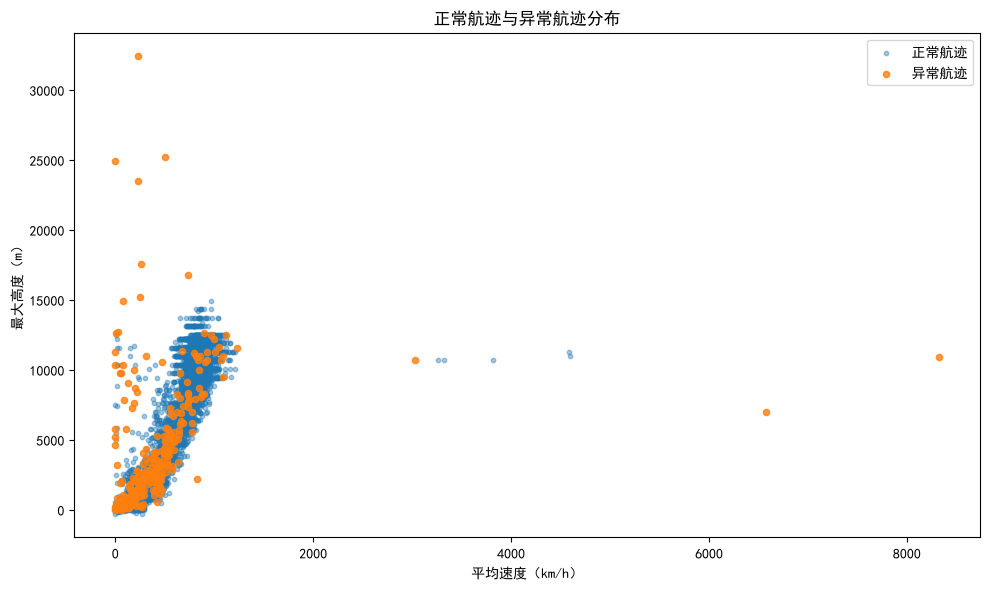

In [38]:
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']   
plt.rcParams['axes.unicode_minus'] = False   

normal = flight_features[
    flight_features["anomaly_label"] == 1
]

abnormal = flight_features[
    flight_features["anomaly_label"] == -1
]

plt.figure(figsize=(10, 6))

plt.scatter(
    normal["avg_speed_kmh"],
    normal["max_altitude_m"],
    s=10,
    alpha=0.4,
    label="正常航迹"
)

plt.scatter(
    abnormal["avg_speed_kmh"],
    abnormal["max_altitude_m"],
    s=20,
    alpha=0.8,
    label="异常航迹"
)

plt.xlabel("平均速度（km/h）")
plt.ylabel("最大高度（m）")
plt.title("正常航迹与异常航迹分布")
plt.legend()

plt.tight_layout()
plt.show()


In [39]:
top_anomalies = (
    flight_features
    .sort_values("anomaly_score")
    .head(10)
)

display(
    top_anomalies[
        [
            "icao24",
            "flight_duration_s",
            "distance_km",
            "avg_speed_kmh",
            "max_speed_kmh",
            "max_altitude_m",
            "altitude_change_m",
            "max_vertical_rate",
            "total_heading_change",
            "max_heading_change",
            "anomaly_score"
        ]
    ]
)

,icao24,flight_duration_s,distance_km,avg_speed_kmh,max_speed_kmh,max_altitude_m,altitude_change_m,max_vertical_rate,total_heading_change,max_heading_change,anomaly_score
1825,7c68ce,303,6.129293,73.540800,314.280,14935.20,14752.32,14.31,338.25,101.25,-0.133762
1297,76e727,303,36.586454,481.608000,524.088,3093.72,411.48,36.09,546.22,176.33,-0.130142
4234,a59b5e,303,19.070547,225.050400,404.028,23500.08,23484.84,19.51,212.52,83.90,-0.130077
5292,ab1534,303,43.239464,495.270000,713.448,4373.88,4244.34,24.06,359.21,173.22,-0.129252
1735,7c42d5,201,0.086920,1.455429,3.708,30.48,0.00,NaN,691.88,163.13,-0.109614
1676,7c1ac8,303,16.441037,193.975200,250.776,1074.42,190.50,53.32,561.17,168.35,-0.106278
3564,a31111,303,27.800088,342.626400,555.408,3429.00,3025.14,17.88,548.75,168.75,-0.105156
5841,ac8b2e,303,23.661211,278.344800,521.208,4076.70,3680.46,26.01,267.04,141.36,-0.104639
4707,a80162,303,26.408372,310.143600,568.512,3695.70,3688.08,20.81,216.72,177.18,-0.099180
3686,a36b2d,201,21.604908,391.428000,523.548,2689.86,2621.28,17.23,258.88,91.92,-0.089495


In [43]:
display(
    anomaly_track[
        [
            "snapshot_time",
            "latitude",
            "longitude",
            "baro_altitude",
            "velocity",
            "true_track",
            "vertical_rate"
        ]
    ]
)

,snapshot_time,latitude,longitude,baro_altitude,velocity,true_track,vertical_rate
4351,1794972621,-36.0690,146.9540,NaN,0.00,216.56,NaN
10976,1794972653,-36.0690,146.9540,14935.20,0.00,216.56,NaN
17596,1794972689,-36.0687,146.9537,NaN,2.06,317.81,NaN
24234,1794972723,-36.0686,146.9529,NaN,4.12,261.56,NaN
30860,1794972754,-36.0689,146.9510,NaN,4.37,261.56,NaN
37452,1794972791,-36.0690,146.9495,NaN,1.03,267.19,NaN
44032,1794972816,-36.0683,146.9491,NaN,3.86,354.38,NaN
50584,1794972850,-36.0677,146.9517,NaN,26.75,81.56,NaN
57142,1794972875,-36.0654,146.9705,182.88,74.79,82.09,14.31
63681,1794972924,-36.0603,147.0108,655.32,87.30,81.87,0.00


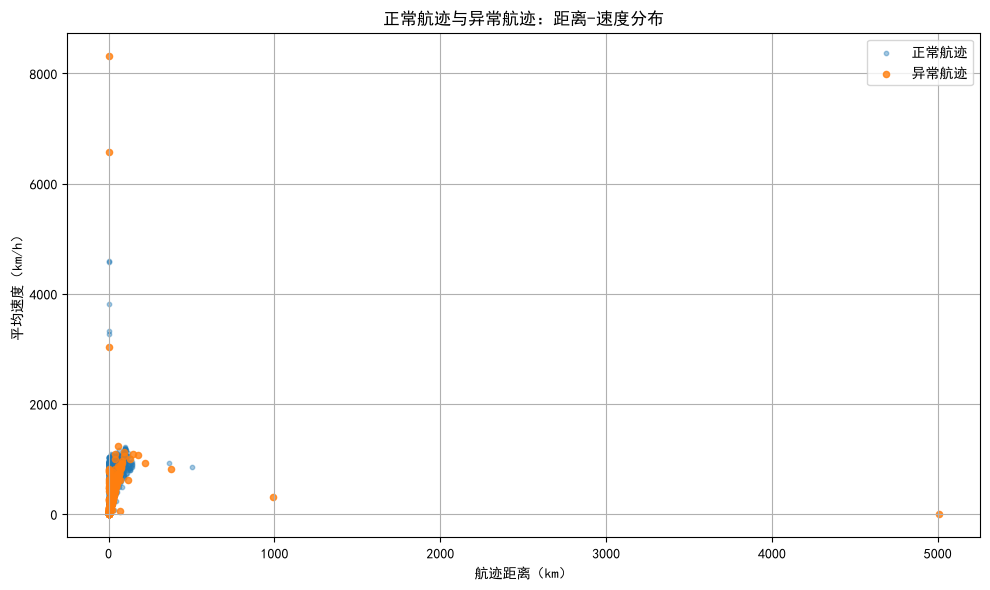

In [47]:
plt.figure(figsize=(10, 6))

plt.scatter(
    normal["distance_km"],
    normal["avg_speed_kmh"],
    s=10,
    alpha=0.4,
    label="正常航迹"
)

plt.scatter(
    abnormal["distance_km"],
    abnormal["avg_speed_kmh"],
    s=20,
    alpha=0.8,
    label="异常航迹"
)

plt.xlabel("航迹距离（km）")
plt.ylabel("平均速度（km/h）")
plt.title("正常航迹与异常航迹：距离-速度分布")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

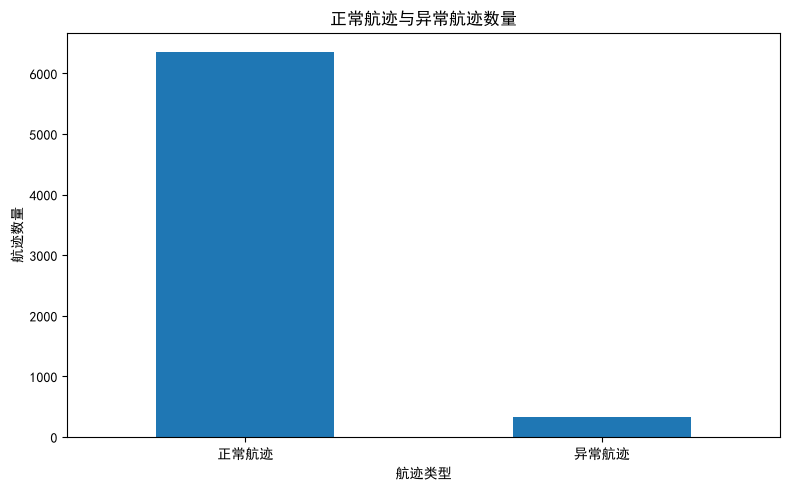

In [48]:
label_count = flight_features["anomaly_label"].value_counts()

label_count.index = ["异常航迹" if x == -1 else "正常航迹"
                     for x in label_count.index]

label_count.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("正常航迹与异常航迹数量")
plt.xlabel("航迹类型")
plt.ylabel("航迹数量")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [49]:
anomaly_result_path = (
    "D:/adsb-flight-analysis/data/processed/anomalies.csv"
)

anomalies.to_csv(
    anomaly_result_path,
    index=False,
    encoding="utf-8-sig"
)

print("异常航迹数据保存成功！")

异常航迹数据保存成功！


In [50]:
trajectory_path = (
    "D:/adsb-flight-analysis/data/processed/trajectory.csv"
)

df_trajectory.to_csv(
    trajectory_path,
    index=False,
    encoding="utf-8-sig"
)

print("航迹数据保存成功！")

航迹数据保存成功！


In [3]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

cluster_features = [
    "flight_duration_s",
    "distance_km",
    "avg_speed_kmh",
    "max_altitude_m",
    "altitude_change_m",
    "total_heading_change"
]

X_cluster = flight_features[cluster_features].copy()

X_cluster = X_cluster.fillna(X_cluster.median())

print("聚类样本数量：", len(X_cluster))

聚类样本数量： 6689


In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_cluster)

In [5]:
dbscan = DBSCAN(
    eps=0.8,
    min_samples=10
)

clusters = dbscan.fit_predict(X_scaled)

flight_features["cluster"] = clusters

In [6]:
print("聚类结果：")

print(
    flight_features["cluster"].value_counts().sort_index()
)

聚类结果：
cluster
-1     203
 0    5889
 1     179
 2     129
 3     134
 4      84
 5      71
Name: count, dtype: int64


In [7]:
cluster_summary = (
    flight_features
    .groupby("cluster")[cluster_features]
    .mean()
)

display(cluster_summary)

,flight_duration_s,distance_km,avg_speed_kmh,max_altitude_m,altitude_change_m,total_heading_change
cluster,,,,,,
-1,250.773399,57.523609,535.786778,5695.077318,2673.853743,190.215419
0,303.000000,48.436432,600.770014,7496.482101,703.977848,44.649170
1,245.519553,6.388394,498.348559,4879.515172,42.917241,8.741061
2,160.620155,0.153564,18.788933,9560.560000,0.000000,24.004341
3,186.350746,9.887165,548.886601,5619.205714,54.912381,3.544403
4,133.000000,6.528393,545.534057,5051.589630,174.413333,7.394048
5,244.901408,0.116884,25.335132,NaN,NaN,7.645775


In [8]:
#由于cluster5有缺失值，先检查有多少缺失值
print(
    flight_features[
        flight_features["cluster"] == 5
    ][cluster_features].isnull().sum()
)

flight_duration_s        0
distance_km              0
avg_speed_kmh            0
max_altitude_m          71
altitude_change_m       71
total_heading_change     0
dtype: int64


In [9]:
#cluster 5数据条数：
print(
    "Cluster 5 样本数：",
    (flight_features["cluster"] == 5).sum()
)

Cluster 5 样本数： 71


In [10]:
#由于缺失值较多，不能直接用中位数填充。重新聚类
cluster_features = [
    "flight_duration_s",
    "distance_km",
    "avg_speed_kmh",
    "max_altitude_m",
    "altitude_change_m",
    "total_heading_change"
]

X_cluster = flight_features[cluster_features].copy()

# 不填充 NaN，直接排除关键特征缺失的样本
X_cluster_valid = X_cluster.dropna()

print("全部航迹：", len(X_cluster))
print("参与DBSCAN：", len(X_cluster_valid))
print("暂不参与：", len(X_cluster) - len(X_cluster_valid))

全部航迹： 6689
参与DBSCAN： 6031
暂不参与： 658


发现暂不参与聚类的航迹过多，检查原数据的特征缺失数量

In [11]:
missing_count = X_cluster.isnull().sum()

print("各特征缺失数量：")
print(missing_count)

各特征缺失数量：
flight_duration_s         0
distance_km               0
avg_speed_kmh             0
max_altitude_m          658
altitude_change_m       658
total_heading_change      0
dtype: int64


缺失的特征都是最高高度以及高度变化，重新开始聚类，把高度相关特征从聚类中去除

In [13]:
cluster_features = [
    "flight_duration_s",
    "distance_km",
    "avg_speed_kmh",
    "total_heading_change"
]

X_cluster = flight_features[cluster_features].copy()

print("参与DBSCAN的航迹数：", len(X_cluster))
print("缺失值数量：")
print(X_cluster.isnull().sum())

参与DBSCAN的航迹数： 6689
缺失值数量：
flight_duration_s       0
distance_km             0
avg_speed_kmh           0
total_heading_change    0
dtype: int64


In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_cluster)

print("标准化完成")
print("数据形状：", X_scaled.shape)

标准化完成
数据形状： (6689, 4)


In [15]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.8,
    min_samples=10
)

clusters = dbscan.fit_predict(X_scaled)

print("DBSCAN 聚类完成")
print("聚类标签：", sorted(set(clusters)))

DBSCAN 聚类完成
聚类标签： [np.int64(-1), np.int64(0), np.int64(1), np.int64(2)]


In [16]:
flight_features["cluster"] = clusters

print(
    flight_features["cluster"].value_counts().sort_index()
)

cluster
-1      37
 0    5941
 1     395
 2     316
Name: count, dtype: int64


### DBSCAN 聚类结果

| Cluster | 数量 | 占比 | 含义 |
|---:|---:|---:|---|
| -1 | 37 | 0.55% | DBSCAN 认为是噪声/孤立样本 |
| 0 | 5941 | 88.82% | 主要飞行模式 |
| 1 | 395 | 5.91% | 第二类飞行模式 |
| 2 | 316 | 4.72% | 第三类飞行模式 |
| **合计** | **6689** | **100%** | **全部航迹** |

**结论：** DBSCAN 将 6689 条航迹划分为 3 个主要聚类，并识别出 37 条噪声/孤立样本。其中 Cluster 0 占比最高（88.82%），是数据集中的主要飞行模式；Cluster 1 和 Cluster 2 分别占 5.91% 和 4.72%，代表规模较小的飞行模式。

In [22]:
#现在已知有3类飞行模式，要通过各个聚类中的特征确定三类飞行模式分别对应什么
#分别取中位数与平均值
cluster_features = [
    "flight_duration_s",
    "distance_km",
    "avg_speed_kmh",
    "total_heading_change"
]
cluster_summary = (
    flight_features
    .groupby("cluster")[cluster_features]
    .median()
    .round(2)
)

display(cluster_summary)

cluster_mean = (
    flight_features
    .groupby("cluster")[cluster_features]
    .mean()
    .round(2)
)

display(cluster_mean)

,flight_duration_s,distance_km,avg_speed_kmh,total_heading_change
cluster,,,,
-1,303.0,1.88,106.61,267.18
0,303.0,59.08,728.37,3.20
1,170.0,0.00,257.22,0.00
2,254.0,0.00,258.89,0.00


,flight_duration_s,distance_km,avg_speed_kmh,total_heading_change
cluster,,,,
-1,265.30,207.82,1202.42,404.37
0,303.00,48.21,598.08,46.56
1,165.83,6.96,355.12,21.29
2,246.94,9.78,384.56,24.81


In [7]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0

    lat1 = np.radians(lat1)
    lat2 = np.radians(lat2)

    dlat = lat2 - lat1
    dlon = np.radians(lon2 - lon1)

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

df_check = df_trajectory.sort_values(
    ["icao24", "snapshot_time"]
).copy()

df_check["prev_latitude"] = (
    df_check.groupby("icao24")["latitude"].shift(1)
)

df_check["prev_longitude"] = (
    df_check.groupby("icao24")["longitude"].shift(1)
)

df_check["segment_distance_km"] = haversine(
    df_check["prev_latitude"],
    df_check["prev_longitude"],
    df_check["latitude"],
    df_check["longitude"]
)

print(df_check.shape)
display(
    df_check[
        [
            "icao24",
            "snapshot_time",
            "latitude",
            "longitude",
            "prev_latitude",
            "prev_longitude",
            "segment_distance_km"
        ]
    ].head(10)
)

(64692, 22)


,icao24,snapshot_time,latitude,longitude,prev_latitude,prev_longitude,segment_distance_km
0,00b1f4,1794972621,-31.6585,114.7344,NaN,NaN,NaN
1,00b1f4,1794972653,-31.6661,114.7882,-31.6585,114.7344,5.161515
2,00b1f4,1794972689,-31.6638,114.8464,-31.6661,114.7882,5.514075
3,00b1f4,1794972723,-31.6611,114.9023,-31.6638,114.8464,5.299120
4,00b1f4,1794972754,-31.6585,114.9498,-31.6611,114.9023,4.505012
5,00b1f4,1794972791,-31.6551,115.0058,-31.6585,114.9498,5.313861
6,00b1f4,1794972816,-31.6529,115.0448,-31.6551,115.0058,3.699554
7,00b1f4,1794972850,-31.6499,115.0987,-31.6529,115.0448,5.112820
8,00b1f4,1794972875,-31.6475,115.1375,-31.6499,115.0987,3.682419
9,00b1f4,1794972924,-31.6435,115.2114,-31.6475,115.1375,7.009604


In [8]:
distance_new = (
    df_check
    .groupby("icao24")["segment_distance_km"]
    .sum()
    .rename("distance_km_new")
)

display(distance_new.describe())

count    6689.000000
mean       44.844422
std        68.964995
min         0.000000
25%        13.800831
50%        53.036855
75%        69.028640
max      5004.118792
Name: distance_km_new, dtype: float64

max      5004.118792明显不符合现实情况，可能是因为时间戳格式错误导致

In [18]:
# 重新从原始轨迹数据创建检查表
df_check = df_trajectory.sort_values(
    ["icao24", "snapshot_time"]
).copy()

# 计算前一个位置
df_check["prev_latitude"] = (
    df_check.groupby("icao24")["latitude"].shift(1)
)

df_check["prev_longitude"] = (
    df_check.groupby("icao24")["longitude"].shift(1)
)

# 计算相邻位置距离
df_check["segment_distance_km"] = haversine(
    df_check["prev_latitude"],
    df_check["prev_longitude"],
    df_check["latitude"],
    df_check["longitude"]
)

# 正确转换时间戳，单位必须是秒
df_check["snapshot_datetime"] = pd.to_datetime(
    df_check["snapshot_time"],
    unit="s"
)

# 计算时间间隔
df_check["time_diff_s"] = (
    df_check.groupby("icao24")["snapshot_datetime"]
    .diff()
    .dt.total_seconds()
)

# 计算相邻航段速度
df_check["segment_speed_kmh"] = (
    df_check["segment_distance_km"]
    / df_check["time_diff_s"]
    * 3600
)

In [19]:
print(df_check[[
    "icao24",
    "snapshot_time",
    "snapshot_datetime",
    "time_diff_s"
]].head(10))

print(df_check.dtypes[[
    "snapshot_time",
    "snapshot_datetime",
    "time_diff_s"
]])


   icao24  snapshot_time   snapshot_datetime  time_diff_s
0  00b1f4     1794972621 2026-11-18 03:30:21          NaN
1  00b1f4     1794972653 2026-11-18 03:30:53         32.0
2  00b1f4     1794972689 2026-11-18 03:31:29         36.0
3  00b1f4     1794972723 2026-11-18 03:32:03         34.0
4  00b1f4     1794972754 2026-11-18 03:32:34         31.0
5  00b1f4     1794972791 2026-11-18 03:33:11         37.0
6  00b1f4     1794972816 2026-11-18 03:33:36         25.0
7  00b1f4     1794972850 2026-11-18 03:34:10         34.0
8  00b1f4     1794972875 2026-11-18 03:34:35         25.0
9  00b1f4     1794972924 2026-11-18 03:35:24         49.0
snapshot_time                 int64
snapshot_datetime    datetime64[us]
time_diff_s                 float64
dtype: object


In [20]:
df_check[
    [
        "icao24",
        "snapshot_datetime",
        "time_diff_s",
        "segment_distance_km",
        "segment_speed_kmh"
    ]
].sort_values(
    "segment_speed_kmh",
    ascending=False
).head(20)

,icao24,snapshot_datetime,time_diff_s,segment_distance_km,segment_speed_kmh
30708,a143e9,2026-11-18 03:35:24,49.0,5003.776994,367624.432239
25839,896740,2026-11-18 03:32:34,31.0,614.376811,71346.984550
12934,780561,2026-11-18 03:34:10,34.0,484.011719,51248.299615
8967,508429,2026-11-18 03:32:03,34.0,354.053140,37487.979523
2753,151dc2,2026-11-18 03:34:10,34.0,344.661109,36493.529224
25842,896740,2026-11-18 03:34:10,34.0,309.477236,32768.177920
5590,4246be,2026-11-18 03:34:10,34.0,202.908380,21484.416716
992,06a140,2026-11-18 03:33:36,25.0,114.329253,16463.412486
25868,896746,2026-11-18 03:32:03,34.0,131.269213,13899.093104
62434,c0809e,2026-11-18 03:33:36,25.0,80.149936,11541.590783


In [21]:
df_check["segment_speed_kmh"].describe()

count     57640.000000
mean        552.701327
std        1657.934388
min           0.000000
25%         158.142507
50%         654.996225
75%         828.854925
max      367624.432239
Name: segment_speed_kmh, dtype: float64

In [22]:
# 统计不同速度阈值下的异常航段数量
thresholds = [1000, 1200, 1500, 2000, 3000]

for t in thresholds:
    count = (
        df_check["segment_speed_kmh"] > t
    ).sum()

    print(f"超过 {t} km/h 的航段数量：{count}")

超过 1000 km/h 的航段数量：2229
超过 1200 km/h 的航段数量：751
超过 1500 km/h 的航段数量：476
超过 2000 km/h 的航段数量：309
超过 3000 km/h 的航段数量：160


In [23]:
df_check[
    [
        "icao24",
        "snapshot_datetime",
        "time_diff_s",
        "segment_distance_km",
        "segment_speed_kmh"
    ]
].sort_values(
    "segment_speed_kmh",
    ascending=False
).head(20)

,icao24,snapshot_datetime,time_diff_s,segment_distance_km,segment_speed_kmh
30708,a143e9,2026-11-18 03:35:24,49.0,5003.776994,367624.432239
25839,896740,2026-11-18 03:32:34,31.0,614.376811,71346.984550
12934,780561,2026-11-18 03:34:10,34.0,484.011719,51248.299615
8967,508429,2026-11-18 03:32:03,34.0,354.053140,37487.979523
2753,151dc2,2026-11-18 03:34:10,34.0,344.661109,36493.529224
25842,896740,2026-11-18 03:34:10,34.0,309.477236,32768.177920
5590,4246be,2026-11-18 03:34:10,34.0,202.908380,21484.416716
992,06a140,2026-11-18 03:33:36,25.0,114.329253,16463.412486
25868,896746,2026-11-18 03:32:03,34.0,131.269213,13899.093104
62434,c0809e,2026-11-18 03:33:36,25.0,80.149936,11541.590783


有一部分 ADS-B 航迹点出现了不合理的位置跳变

In [24]:
#第一步：统计每架飞机的异常航段数量
# 统计每架飞机超过1500 km/h的航段数量
abnormal_segments = (
    df_check[df_check["segment_speed_kmh"] > 1500]
    .groupby("icao24")
    .size()
    .sort_values(ascending=False)
)

print("存在异常航段的飞机数量：", len(abnormal_segments))
print("\n异常航段数量最多的20架飞机：")
display(abnormal_segments.head(20))

存在异常航段的飞机数量： 373

异常航段数量最多的20架飞机：


icao24
896740    4
780a18    4
a77035    3
a8397c    3
39cf0c    3
a06f5a    3
899043    3
a6a6fe    3
06a2eb    3
750440    3
3c6716    3
7c78a9    3
34740f    2
c04394    2
aa7f48    2
3949e6    2
39d2b0    2
a5fd2d    2
344344    2
a8c121    2
dtype: int64

In [25]:
top_aircraft = abnormal_segments.head(10).index

display(
    df_check[
        df_check["icao24"].isin(top_aircraft)
        & (df_check["segment_speed_kmh"] > 1500)
    ][
        [
            "icao24",
            "snapshot_datetime",
            "time_diff_s",
            "segment_distance_km",
            "segment_speed_kmh"
        ]
    ].sort_values(
        ["icao24", "snapshot_datetime"]
    )
)

,icao24,snapshot_datetime,time_diff_s,segment_distance_km,segment_speed_kmh
1177,06a2eb,2026-11-18 03:32:03,34.0,20.721230,2194.012614
1178,06a2eb,2026-11-18 03:32:34,31.0,16.023105,1860.747632
1182,06a2eb,2026-11-18 03:34:35,25.0,20.972331,3020.015693
3929,39cf0c,2026-11-18 03:32:03,34.0,31.887473,3376.320706
3933,39cf0c,2026-11-18 03:34:10,34.0,17.906898,1896.024517
3935,39cf0c,2026-11-18 03:35:24,49.0,24.046545,1766.684957
11216,750440,2026-11-18 03:32:34,31.0,63.100129,7327.756963
11218,750440,2026-11-18 03:33:36,25.0,14.047760,2022.877438
11221,750440,2026-11-18 03:35:24,49.0,30.532531,2243.206383
13282,780a18,2026-11-18 03:30:53,32.0,20.720510,2331.057399


In [26]:
# 查看异常航段前后的坐标
check_id = "896740"

display(
    df_check[
        df_check["icao24"] == check_id
    ][
        [
            "icao24",
            "snapshot_datetime",
            "latitude",
            "longitude",
            "prev_latitude",
            "prev_longitude",
            "segment_distance_km",
            "segment_speed_kmh"
        ]
    ].round(4)
)

C:\Users\COLORFUL\AppData\Local\Temp\ipykernel_10608\1955135854.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4)


,icao24,snapshot_datetime,latitude,longitude,prev_latitude,prev_longitude,segment_distance_km,segment_speed_kmh
25835,896740,2026-11-18 03:30:21,14.6321,97.9062,NaN,NaN,NaN,NaN
25836,896740,2026-11-18 03:30:53,14.6321,97.9062,14.6321,97.9062,0.0000,0.0000
25837,896740,2026-11-18 03:31:29,14.6321,97.9062,14.6321,97.9062,0.0000,0.0000
25838,896740,2026-11-18 03:32:03,14.6321,97.9062,14.6321,97.9062,0.0000,0.0000
25839,896740,2026-11-18 03:32:34,19.8932,96.1379,14.6321,97.9062,614.3768,71346.9845
25840,896740,2026-11-18 03:33:11,19.7334,96.4500,19.8932,96.1379,37.1716,3616.6945
25841,896740,2026-11-18 03:33:36,19.8946,96.2098,19.7334,96.4500,30.8658,4444.6747
25842,896740,2026-11-18 03:34:10,20.3549,93.2864,19.8946,96.2098,309.4772,32768.1779
25843,896740,2026-11-18 03:34:35,20.3549,93.2864,20.3549,93.2864,0.0000,0.0000
25844,896740,2026-11-18 03:35:24,20.3549,93.2864,20.3549,93.2864,0.0000,0.0000


In [27]:
# 不同速度区间的航段数量
speed_bins = [
    0, 1000, 1500, 2000, 3000,
    5000, 10000, float("inf")
]

speed_labels = [
    "0-1000",
    "1000-1500",
    "1500-2000",
    "2000-3000",
    "3000-5000",
    "5000-10000",
    "10000以上"
]

speed_distribution = pd.cut(
    df_check["segment_speed_kmh"],
    bins=speed_bins,
    labels=speed_labels,
    right=False
).value_counts().sort_index()

display(speed_distribution)

segment_speed_kmh
0-1000        55411
1000-1500      1753
1500-2000       167
2000-3000       149
3000-5000        94
5000-10000       56
10000以上          10
Name: count, dtype: int64

In [28]:
# 标记有效航段
df_check["is_valid_segment"] = (
    df_check["segment_speed_kmh"].notna()
    & (df_check["segment_speed_kmh"] >= 0)
    & (df_check["segment_speed_kmh"] <= 1500)
)

# 标记异常航段
df_check["is_abnormal_segment"] = (
    df_check["segment_speed_kmh"] > 1500
)

# 统计清洗情况
print("有效航段数量：", df_check["is_valid_segment"].sum())
print("异常航段数量：", df_check["is_abnormal_segment"].sum())
print(
    "有效航段占比：",
    round(df_check["is_valid_segment"].mean() * 100, 2),
    "%"
)

有效航段数量： 57164
异常航段数量： 476
有效航段占比： 88.36 %


In [30]:
# 筛选有效航段
df_valid_segments = df_check[
    df_check["is_valid_segment"]
].copy()

# 按航空器汇总
clean_segment_features = (
    df_valid_segments
    .groupby("icao24")
    .agg(
        distance_km_clean=("segment_distance_km", "sum"),
        valid_time_s=("time_diff_s", "sum"),
        max_speed_kmh_clean=("segment_speed_kmh", "max"),
        valid_segment_count=("segment_speed_kmh", "count")
    )
    .reset_index()
)

# 计算有效航段平均速度
clean_segment_features["avg_speed_kmh_clean"] = (
    clean_segment_features["distance_km_clean"]
    / clean_segment_features["valid_time_s"]
    * 3600
)

print("批量清洗完成！")
print("航空器数量：", len(clean_segment_features))
print("有效航段数量：", clean_segment_features["valid_segment_count"].sum())

批量清洗完成！
航空器数量： 6652
有效航段数量： 57164


In [33]:
# 保留原有飞行时间、高度、航向等特征
flight_features_clean = flight_features.drop(
    columns=[
        "distance_km",
        "avg_speed_kmh",
        "max_speed_kmh"
    ],
    errors="ignore"
).merge(
    clean_segment_features,
    on="icao24",
    how="left"
)

# 使用清洗后的距离和速度
flight_features_clean["distance_km"] = (
    flight_features_clean["distance_km_clean"]
)

flight_features_clean["avg_speed_kmh"] = (
    flight_features_clean["avg_speed_kmh_clean"]
)

flight_features_clean["max_speed_kmh"] = (
    flight_features_clean["max_speed_kmh_clean"]
)

print("特征合并完成！")
print("总航空器数量：", len(flight_features_clean))

特征合并完成！
总航空器数量： 6689


In [34]:
flight_features_clean.to_csv(
    "D:/adsb-flight-analysis/data/processed/flight_features_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

print("文件保存成功！")

文件保存成功！


In [35]:
import pandas as pd
from sklearn.ensemble import IsolationForest

# 读取清洗后的特征
flight_features_clean = pd.read_csv(
    "D:/adsb-flight-analysis/data/processed/flight_features_clean.csv"
)

# 选择模型特征
features = [
    "flight_duration_s",
    "distance_km",
    "avg_speed_kmh",
    "max_altitude_m",
    "altitude_change_m",
    "max_vertical_rate",
    "total_heading_change",
    "max_heading_change"
]

# 准备数据
X = flight_features_clean[features].copy()
X = X.fillna(X.median())

# 训练 Isolation Forest
model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

flight_features_clean["anomaly_label"] = model.fit_predict(X)
flight_features_clean["anomaly_score"] = model.decision_function(X)

# 统计结果
print("异常检测完成！")
print(flight_features_clean["anomaly_label"].value_counts())

异常检测完成！
anomaly_label
 1    6354
-1     335
Name: count, dtype: int64


In [36]:
flight_features_clean.to_csv(
    "D:/adsb-flight-analysis/data/processed/flight_anomaly_results_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

print("新的异常检测结果保存成功！")

新的异常检测结果保存成功！


In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

cluster_features = [
    "flight_duration_s",
    "distance_km",
    "avg_speed_kmh",
    "total_heading_change"
]

X_cluster = flight_features_clean[cluster_features].copy()
X_cluster = X_cluster.fillna(X_cluster.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

dbscan = DBSCAN(
    eps=0.8,
    min_samples=10
)

flight_features_clean["cluster"] = dbscan.fit_predict(X_scaled)

print("DBSCAN 聚类完成！")
print(flight_features_clean["cluster"].value_counts().sort_index())

flight_features_clean.to_csv(
    "D:/adsb-flight-analysis/data/processed/flight_clustering_results_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

print("聚类结果保存成功！")

DBSCAN 聚类完成！
cluster
-1      30
 0    5955
 1     389
 2     315
Name: count, dtype: int64
聚类结果保存成功！
